# Лабораторна 2. Від сирих даних до нейромережі

У цій лабораторній роботі ви пройдете повний цикл роботи з табличним датасетом для задачі регресії — від завантаження до порівняння моделей:

- дослідницький аналіз даних (EDA): загальний огляд, гістограми, кореляції;
- обробка пропусків і викидів;
- інженерія ознак;
- baseline: множинна лінійна регресія;
- нейромережа — підбір архітектури, функцій активації, оптимізатора власними експериментами;
- чесне порівняння моделей на test за метриками регресії (MSE, RMSE, MAE, R²).

Демо-ноутбук з лекції 3-4 — основа, звертайтесь до нього як до довідника, коли щось незрозуміло. Він лежить в архіві демо-матеріалів лекції 3 — посилання «Демо-матеріали (zip)» є в картці лекції на головній сторінці курсу.

**Домбровський Богдан Володимирович**

## 0. Опрацюйте демо-ноутбук з лекції
Прогляньте пояснення ноутбуку і запустіть всі клітинки демо-ноутбуку (крім тих секцій, в яких вказано, що їх запускати не можна).
Після цього дайте тут відповідь на запитання:
1. Чому для заповнення пропусків було обрано метод kNN?
2. Чому при тренуванні лінійної регресії train і val порівнюються лише на основі MSE, а після тренування на основі багатьох функцій? Проекспериментуйте в межах тренування з вибором функції і поділіться результатами.
3. Які висновки після клітинки 2.6 в демо Ви можете зробити?
4. Поясни для чого потрібен baseline в лінійній регресії і як він вираховується? Що є baseline для нейронної мережі?
5. Продемонструй дію всіх функцій активації на графіку функцій, згенерувавши 1000 випадкових значень Х і порахувавши для них Y через ці функції.
6. Яким чином в нейронній мережі утворилася така кількість параметрів, яка вказана після виконання 3.3?
7. Чи оптимально вибрано кількість епох в 3.5?

### 0.1. Відповіді
1. kNN враховує зв’язки між ознаками, на відміну від медіани. У демо окремий KNeighborsRegressor навчається на повних рядках train для кожної колонки з пропусками.
2. MSE є диференційовною функцією втрат і сильно штрафує великі помилки. Після навчання RMSE та MAE показують помилки в одиницях таргету, R² — частку поясненої варіації. Нижче порівнюю MSE, MAE та SmoothL1 на однакових даних.
3. У 2.6 ваги стандартизованих ознак можна порівнювати за модулем; знак визначає напрям зв’язку за фіксованих інших ознак. Це не причинність, особливо за мультиколінеарності. Код нижче показує аналогічний аналіз для Abalone.
4. Найпростіший baseline — середнє y_train для всіх прогнозів. Для нейромережі baseline — навчена множинна лінійна регресія.
5. Графік чотирьох активацій наведено нижче.
6. Для n входів мережа n→64→32→1 має (n+1)·64 + (64+1)·32 + (32+1) параметрів. ReLU не має параметрів.
7. У демо 200 епох не обов’язково оптимальні: за текстом 3.9 обидві криві ще спадають. Варто перевірити більше епох і вибрати чекпоінт за validation, не test.

In [1]:
%pip install -q datasets tensorboard gradio scikit-learn matplotlib pandas torch


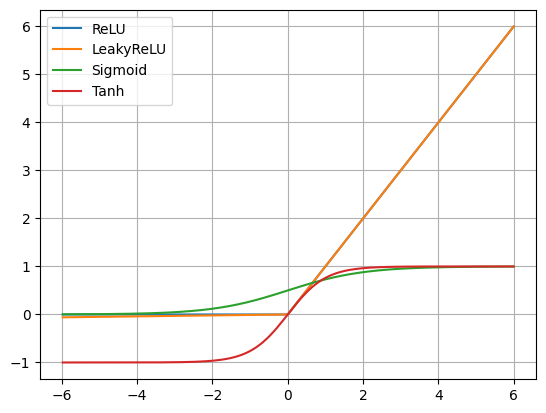

In [2]:
import hashlib, random, copy, shutil, os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.tensorboard import SummaryWriter
from datasets import load_dataset
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from IPython.display import display
SEED=42
def seed():
    random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
seed(); torch.set_num_threads(2)
x=torch.sort(torch.rand(1000)*12-6).values
for f in [nn.ReLU(),nn.LeakyReLU(),nn.Sigmoid(),nn.Tanh()]:
    plt.plot(x.numpy(),f(x).numpy(),label=type(f).__name__)
plt.legend(); plt.grid(); plt.show()


---
## 1. Датасети

Ви отримаєте один з 10 датасетів нижче. Усі — задачі регресії на Hugging Face: табличні дані, здебільшого числові ознаки, від кількасот до кількадесяти тисяч рядків.

1. **[King County House Sales](https://huggingface.co/datasets/kraina/house_sales_in_king_county)** — 21 613 продажів будинків (Вашингтон, 2014–2015). Таргет: `price`. ⚠️ `load_dataset("kraina/house_sales_in_king_county")` не працює (застарілий loading-скрипт) — вантажте напряму: `load_dataset("parquet", data_files="https://huggingface.co/datasets/kraina/house_sales_in_king_county/resolve/main/data/house_sales_king_county.parquet")`.
2. **[Diamonds](https://huggingface.co/datasets/jdxcosta/diamonds)** — 53 940 діамантів. Таргет: `price`. Ознаки: вага (`carat`), огранка, колір, чистота, розміри.
3. **[Concrete Compressive Strength](https://huggingface.co/datasets/foundry-ml/dataset_concrete_compressive_strength)** — 1 030 замісів бетону. Таргет: міцність на стиск. Усі ознаки числові (склад суміші + вік).
4. **[Auto MPG](https://huggingface.co/datasets/scikit-learn/auto-mpg)** — 398 автомобілів. Таргет: `mpg` (витрата пального). Найменший і найпростіший датасет зі списку.
5. **[Wine Quality](https://huggingface.co/datasets/codesignal/wine-quality)** — 1 599 (червоне) + 4 898 (біле) вин. Таргет: `quality` (оцінка 3–9). Усі ознаки — хімічний склад, числові.
6. **[Laptop Price](https://huggingface.co/datasets/Ammok/laptop_price_prediction)** — 977 + 325 ноутбуків. Таргет: `Price`. Частина ознак текстові (`RAM`, `Storage`, `CPU`) — доведеться парсити в числа.
7. **[Bike Sharing Demand](https://huggingface.co/datasets/t22000t/bike-sharing-tabular)** — 17 379 годинних записів прокату велосипедів. Таргет: `cnt`. Часові й погодні ознаки.
8. **[Ames House Prices](https://huggingface.co/datasets/t22000t/house-prices-tabular)** — 1 460 будинків, 79 ознак. Таргет: `SalePrice`. Найбільше категоріальних ознак зі списку — гарна практика на encoding.
9. **[Medical Insurance Cost](https://huggingface.co/datasets/harishsohani/medical-insurance-cost-prediction)** — 1 338 застрахованих. Таргет: `charges`. Компактний, мало ознак — хороший старт, якщо часу мало. ⚠️ У репозиторії кілька CSV одразу (`Xtrain`/`Xtest`/`insurance.csv`) — вкажіть файл явно: `load_dataset("harishsohani/medical-insurance-cost-prediction", data_files="insurance.csv")`.
10. **[Abalone](https://huggingface.co/datasets/mstz/abalone)** — 4 177 молюсків. Таргет: `number_of_rings` (вік). Усі ознаки — фізичні виміри, окрім `sex`.

Решта (2–5, 7–8, 10) вантажаться напряму — `load_dataset("<repo_id>")` без додаткових аргументів, HF-токен не потрібен.

### 1.1. Який датасет мій?

Визначте самі власний датасет: беремо Ваше ПІБ, рахуємо SHA-256 хеш, залишок від ділення на 10 — це індекс у списку датасетів вище (0 → перший, 9 → останній).

**Формат ПІБ:** точно як у списку групи — `Прізвище Ім'я По-батькові`, по одному пробілу між словами, без зайвих пробілів на початку/в кінці. Якщо використаєте інший формат - **не зарахую лабу**!!!

In [3]:
import hashlib

DATASETS = [
    "King County House Sales",
    "Diamonds",
    "Concrete Compressive Strength",
    "Auto MPG",
    "Wine Quality",
    "Laptop Price",
    "Bike Sharing Demand",
    "Ames House Prices",
    "Medical Insurance Cost",
    "Abalone",
]

FULL_NAME = "Домбровський Богдан Володимирович"  # TODO: впишіть своє ПІБ точно як у списку групи

dataset_index = int(hashlib.sha256(FULL_NAME.encode("utf-8")).hexdigest(), 16) % len(DATASETS)
print(f"Ваш датасет (#{dataset_index + 1}):", DATASETS[dataset_index])

Ваш датасет (#10): Abalone


## 2.1. Підготовка даних
Спліт 60/20/20 до EDA: статистики val/test не використовуються для навчання чи вибору ознак.

In [4]:
ds=load_dataset("mstz/abalone")
df=pd.concat([v.to_pandas() for v in ds.values()],ignore_index=True)
target="number_of_rings"
assert target in df.columns, df.columns
train,temp=train_test_split(df,test_size=.4,random_state=SEED)
val,test=train_test_split(temp,test_size=.5,random_state=SEED)
print(train.shape,val.shape,test.shape)
display(train.head()); train.info(); display(train.describe(include="all")); display(train.isna().sum())


README.md:   0%|          | 0.00/1.60k [00:00<?, ?B/s]

train.csv:   0%|          | 0.00/192k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/4177 [00:00<?, ? examples/s]

(2506, 9) (835, 9) (836, 9)


,sex,length,diameter,height,whole_weight,shucked_weight,viscera_weight,shell_weight,number_of_rings
542,M,0.420,0.325,0.115,0.2885,0.1000,0.0570,0.1135,15
91,M,0.555,0.440,0.150,0.7550,0.3070,0.1525,0.2600,12
4158,I,0.480,0.355,0.110,0.4495,0.2010,0.0890,0.1400,8
3833,M,0.535,0.410,0.150,0.8105,0.3450,0.1870,0.2400,11
1795,F,0.580,0.430,0.170,1.4800,0.6535,0.3240,0.4155,10


<class 'pandas.core.frame.DataFrame'>
Index: 2506 entries, 542 to 860
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   sex              2506 non-null   object 
 1   length           2506 non-null   float64
 2   diameter         2506 non-null   float64
 3   height           2506 non-null   float64
 4   whole_weight     2506 non-null   float64
 5   shucked_weight   2506 non-null   float64
 6   viscera_weight   2506 non-null   float64
 7   shell_weight     2506 non-null   float64
 8   number_of_rings  2506 non-null   int64  
dtypes: float64(7), int64(1), object(1)
memory usage: 195.8+ KB


,sex,length,diameter,height,whole_weight,shucked_weight,viscera_weight,shell_weight,number_of_rings
count,2506,2506.000000,2506.000000,2506.000000,2506.000000,2506.000000,2506.000000,2506.000000,2506.000000
unique,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,M,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,936,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,0.525804,0.409409,0.140211,0.837414,0.363400,0.182429,0.241497,10.019154
std,NaN,0.120392,0.099626,0.043357,0.494864,0.224731,0.109855,0.141131,3.272768
min,NaN,0.075000,0.055000,0.000000,0.002000,0.001000,0.000500,0.001500,1.000000
25%,NaN,0.450000,0.350000,0.115000,0.443250,0.187000,0.094500,0.131000,8.000000
50%,NaN,0.545000,0.425000,0.145000,0.810250,0.342750,0.173500,0.235000,10.000000
75%,NaN,0.615000,0.480000,0.165000,1.154500,0.509000,0.255375,0.330000,11.000000


,0
sex,0
length,0
diameter,0
height,0
whole_weight,0
shucked_weight,0
viscera_weight,0
shell_weight,0
number_of_rings,0


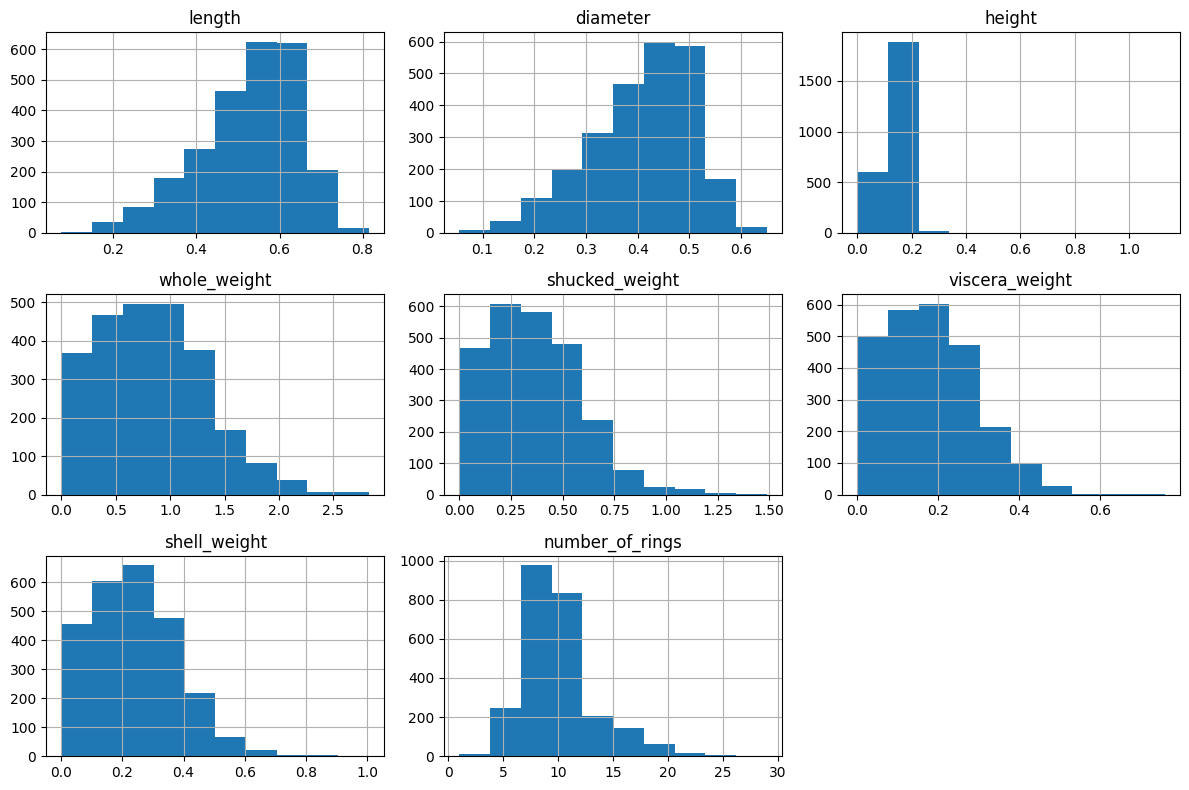

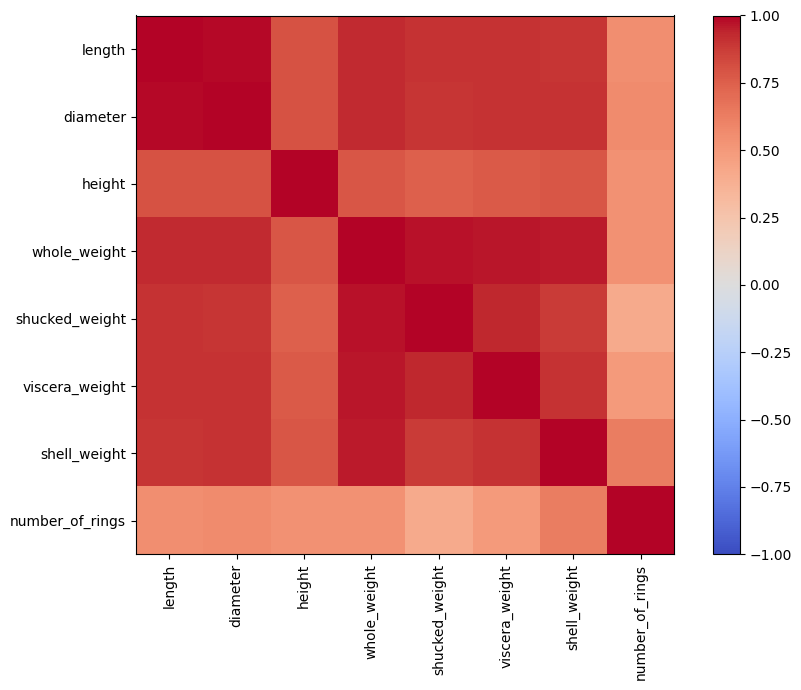

length diameter 0.988
length whole_weight 0.925
length shucked_weight 0.899
length viscera_weight 0.903
length shell_weight 0.894
diameter whole_weight 0.925
diameter shucked_weight 0.895
diameter viscera_weight 0.9
diameter shell_weight 0.9
whole_weight shucked_weight 0.97
whole_weight viscera_weight 0.966
whole_weight shell_weight 0.955
shucked_weight viscera_weight 0.933
shucked_weight shell_weight 0.879
viscera_weight shell_weight 0.904
Пропуски train: 0
length IQR-викиди: 29 частота максимуму: 1
diameter IQR-викиди: 36 частота максимуму: 1
height IQR-викиди: 18 частота максимуму: 1
whole_weight IQR-викиди: 19 частота максимуму: 1
shucked_weight IQR-викиди: 32 частота максимуму: 1
viscera_weight IQR-викиди: 14 частота максимуму: 1
shell_weight IQR-викиди: 25 частота максимуму: 1
number_of_rings IQR-викиди: 182 частота максимуму: 1


In [5]:
train.hist(figsize=(12,8)); plt.tight_layout(); plt.show()
corr=train.select_dtypes(include=np.number).corr()
fig,ax=plt.subplots(figsize=(9,7)); im=ax.imshow(corr,vmin=-1,vmax=1,cmap="coolwarm")
ax.set_xticks(range(len(corr)),corr.columns,rotation=90); ax.set_yticks(range(len(corr)),corr.columns)
fig.colorbar(im); plt.tight_layout(); plt.show()
for i,a in enumerate(corr.columns):
    for b in corr.columns[i+1:]:
        if abs(corr.loc[a,b])>.85: print(a,b,round(corr.loc[a,b],3))
print("Пропуски train:",train.isna().sum().sum())
for c in train.select_dtypes(include=np.number):
    q1,q3=train[c].quantile([.25,.75]); iqr=q3-q1
    print(c,"IQR-викиди:",((train[c]<q1-1.5*iqr)|(train[c]>q3+1.5*iqr)).sum(),"частота максимуму:",(train[c]==train[c].max()).sum())


Розміри та маси молюсків можуть бути сильно корельованими; IQR-викиди самі по собі не доводять помилку вимірювання. Залишаю рідкісні значення та всі фізичні ознаки, щоб не втрачати інформацію. Категоріальну стать кодуємо one-hot; числові ознаки стандартизуємо. Якщо пропуски відсутні, імпутація нічого не змінює; інакше медіана/мода train забезпечують відтворювану обробку.

In [6]:
features=[c for c in train if c!=target]
num=train[features].select_dtypes(include=np.number).columns.tolist()
cat=[c for c in features if c not in num]
# sex може бути представлена числовим кодом категорії
if "sex" in num: num.remove("sex"); cat.append("sex")
prep=ColumnTransformer([("num",make_pipeline(SimpleImputer(strategy="median"),StandardScaler()),num),("cat",make_pipeline(SimpleImputer(strategy="most_frequent"),OneHotEncoder(handle_unknown="ignore",sparse_output=False)),cat)])
X=[prep.fit_transform(train[features]),prep.transform(val[features]),prep.transform(test[features])]
y=[d[target].to_numpy(dtype=np.float32) for d in [train,val,test]]
assert all(np.isfinite(a).all() for a in y)
xt,xv,xs=[torch.tensor(a,dtype=torch.float32) for a in X]
yt,yv,ys=[torch.tensor(a).reshape(-1,1) for a in y]
root=Path.cwd(); root=root if root.name=="lab2" else root/"lab2"
root.mkdir(exist_ok=True); (root/"models").mkdir(exist_ok=True); (root/"runs").mkdir(exist_ok=True)


## 2.2–2.4. Навчання моделей
Дві архітектури, три незалежні зміни гіперпараметрів відносно переможця validation. Зберігаємо найкращий чекпоінт за MSE validation.

linear validation MSE 4.7075
loss_MSE validation MSE 4.7075
loss_MAE validation MSE 6.4312
loss_SmoothL1 validation MSE 6.4538


,0
cat__sex_M,2.787043
cat__sex_F,2.773569
num__shucked_weight,-2.602220
num__shell_weight,2.379178
cat__sex_I,1.909132
num__whole_weight,0.709525
num__diameter,0.699276
num__height,0.489975
num__length,0.332730
num__viscera_weight,-0.306112


nn_v1 validation MSE 4.4097
nn_v2 validation MSE 4.173
nn_v3 validation MSE 4.5851
nn_v4 validation MSE 4.1544
nn_v5 validation MSE 4.3635


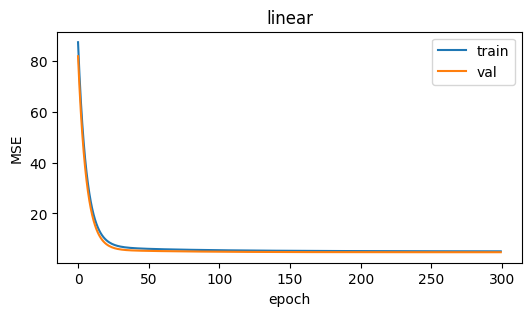

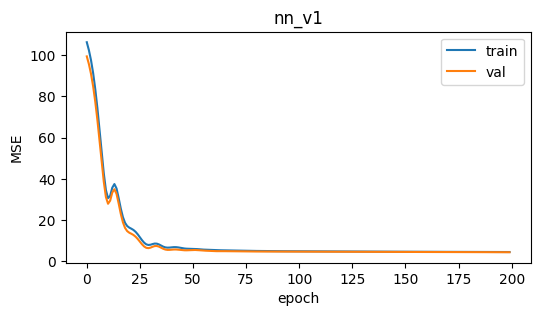

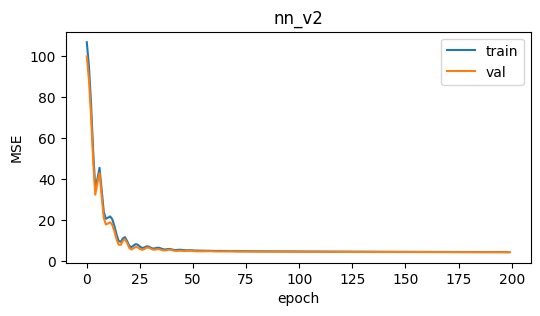

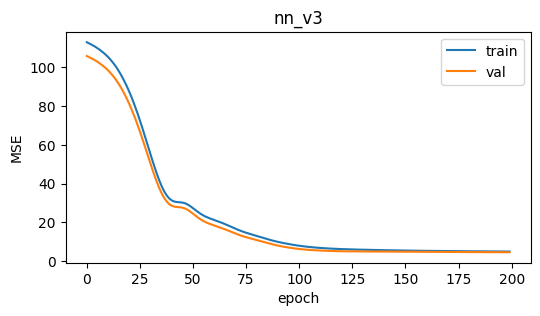

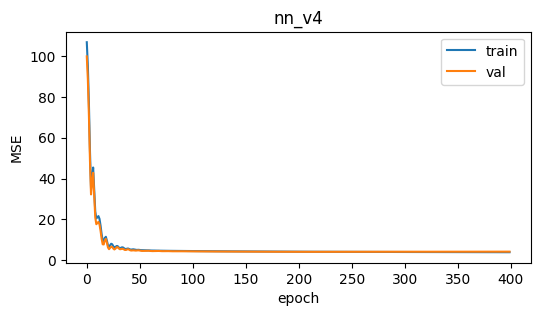

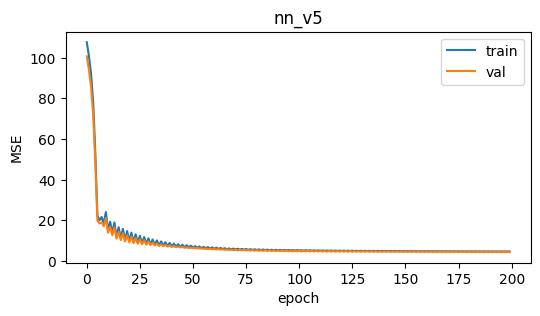

In [7]:
models={}; histories={}; configs={}; scores={}
def fit(name,widths=(),lr=.01,epochs=200,opt="Adam",loss_name="MSE",save=True):
    seed(); layers=[]; d=xt.shape[1]
    for w in widths: layers.extend([nn.Linear(d,w),nn.ReLU()]); d=w
    model=nn.Sequential(*layers,nn.Linear(d,1)) if widths else nn.Linear(d,1)
    optimizer=getattr(torch.optim,opt)(model.parameters(),lr=lr)
    lossfn={"MSE":nn.MSELoss(),"MAE":nn.L1Loss(),"SmoothL1":nn.SmoothL1Loss()}[loss_name]
    writer=SummaryWriter(str(root/"runs"/name)) if save else None
    best=float("inf"); hist=[]
    for epoch in range(epochs):
        model.train(); optimizer.zero_grad(); loss=lossfn(model(xt),yt); loss.backward(); optimizer.step()
        model.eval()
        with torch.no_grad(): a=nn.functional.mse_loss(model(xt),yt).item(); b=nn.functional.mse_loss(model(xv),yv).item()
        hist.append((a,b))
        if writer: writer.add_scalar("Loss/train",a,epoch); writer.add_scalar("Loss/val",b,epoch)
        if b<best: best=b; state=copy.deepcopy(model.state_dict())
    model.load_state_dict(state)
    if writer:
        writer.close(); torch.save(state,root/"models"/(name+".pt")); models[name]=model; histories[name]=hist; scores[name]=best; configs[name]=(widths,lr,epochs,opt)
    print(name,"validation MSE",round(best,4)); return best
fit("linear",lr=.03,epochs=300,opt="SGD")
for loss in ["MSE","MAE","SmoothL1"]: fit("loss_"+loss,lr=.03,epochs=300,opt="SGD",loss_name=loss,save=False)
weights=pd.Series(models["linear"].weight.detach().numpy().ravel(),index=prep.get_feature_names_out()); display(weights.sort_values(key=abs,ascending=False))
fit("nn_v1",(64,32)); fit("nn_v2",(128,64,32))
winner=min(["nn_v1","nn_v2"],key=scores.get); widths,lr,epochs,opt=configs[winner]
fit("nn_v3",widths,lr=.001,epochs=epochs,opt=opt)
fit("nn_v4",widths,lr=lr,epochs=400,opt=opt)
fit("nn_v5",widths,lr=lr,epochs=epochs,opt="SGD")
for name,h in histories.items():
    plt.figure(figsize=(6,3)); plt.plot(h,label=["train","val"]); plt.title(name); plt.ylabel("MSE"); plt.xlabel("epoch"); plt.legend(); plt.show()


## 2.5. Порівняння на test та висновки

In [8]:
def metrics(pred):
    mse=mean_squared_error(y[2],pred)
    return dict(MSE=mse,RMSE=mse**.5,MAE=mean_absolute_error(y[2],pred),R2=r2_score(y[2],pred))
print("Baseline середнього:",metrics(np.full(len(test),y[0].mean())))
with torch.no_grad(): results=pd.DataFrame([dict(model=k,**metrics(m(xs).numpy().ravel())) for k,m in models.items()])
results.to_csv(root/"results.csv",index=False); display(results)
best=min(scores,key=scores.get); r=results.set_index("model"); improvement=100*(1-r.loc[best,"MSE"]/r.loc["linear","MSE"])
print(f"За validation обрано {best}. Зміна test MSE відносно linear: {improvement:.2f}% зменшення (від’ємне значення означає погіршення).")
print("Найменший test MSE:",r.MSE.idxmin())
print("Нейромережа виправдала себе за test MSE:",r.drop(index="linear").MSE.min()<r.loc["linear","MSE"])
print("Ефект архітектури (validation MSE):",scores["nn_v1"]-scores["nn_v2"])
print("Ефекти змін гіперпараметрів (позитивне = покращення):",{k:scores[winner]-scores[k] for k in ["nn_v3","nn_v4","nn_v5"]})
print("TensorBoard: tensorboard --logdir",root/"runs")


Baseline середнього: {'MSE': 9.929869651794434, 'RMSE': 3.1511695688735055, 'MAE': 2.3172364234924316, 'R2': -0.0013301372528076172}


,model,MSE,RMSE,MAE,R2
0,linear,4.846885,2.201564,1.602576,0.511239
1,nn_v1,4.536071,2.129805,1.534447,0.542582
2,nn_v2,4.346273,2.084772,1.482859,0.561721
3,nn_v3,4.798036,2.190442,1.584774,0.516165
4,nn_v4,4.333046,2.081597,1.475502,0.563055
5,nn_v5,4.619134,2.149217,1.480224,0.534206


За validation обрано nn_v4. Зміна test MSE відносно linear: 10.60% зменшення (від’ємне значення означає погіршення).
Найменший test MSE: nn_v4
Нейромережа виправдала себе за test MSE: True
Ефект архітектури (validation MSE): 0.23678112030029297
Ефекти змін гіперпараметрів (позитивне = покращення): {'nn_v3': -0.41216230392456055, 'nn_v4': 0.018562793731689453, 'nn_v5': -0.19058752059936523}
TensorBoard: tensorboard --logdir /content/lab2/runs


## 3. Gradio-застосунок
Прогноз кількості кілець усіма моделями для введених характеристик.

In [9]:
import gradio as gr
inputs=[]
for c in features:
    if c in cat:
        vals=train[c].dropna().unique().tolist(); inputs.append(gr.Dropdown(choices=vals,value=vals[0],label=c))
    else:
        inputs.append(gr.Number(value=float(train[c].median()),label=c))
def predict(*values):
    a=prep.transform(pd.DataFrame([values],columns=features)); t=torch.tensor(a,dtype=torch.float32)
    with torch.no_grad(): preds={k:float(m(t).item()) for k,m in models.items()}
    fig,ax=plt.subplots(figsize=(7,3)); ax.bar(preds.keys(),preds.values()); ax.set_ylabel("Кількість кілець"); fig.tight_layout()
    return preds,fig
app=gr.Interface(fn=predict,inputs=inputs,outputs=[gr.JSON(),gr.Plot()],title="Abalone — порівняння моделей")
app.launch(share=False,prevent_thread_lock=True)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
Note: opening Chrome Inspector may crash demo inside Colab notebooks.
* To create a public link, set `share=True` in `launch()`.


<IPython.core.display.Javascript object>

In [10]:
# Архів для GitHub (включає моделі, логи та CSV; ноутбук збережіть окремо після Run All).
shutil.make_archive(str(root.parent/"lab2_results"),"zip",root.parent,root.name)


'/content/lab2_results.zip'

---
### Як здавати лабу

У форму (https://forms.gle/8Dbc9zB8L5tsNuNEA) здати посилання на **публічний** репозиторій, який містить:

1. **Цей ноутбук з усіма виконаними пунктами**. Має запускатися зверху до низу (Run All) в будь-якому середовищі без помилок.
2. **Файли всіх натренованих варіантів моделі** (2.2-2.4) — лінійна регресія + всі варіанти нейромережі, кожен окремим `.pt` файлом.
3. **Логи TensorBoard** — папка `runs/` з усіма прогонами, щоб можна було відкрити криві навчання, не перезапускаючи ноутбук.
4. **Таблицю результатів** — `results.csv` з порівнянням усіх варіантів (модель, MSE, RMSE, MAE, R² на test).
5. Структура файлів на репозиторії, **точно дотримуйтесь, інакше не зарахується лаба**:
```
/lab2/nn_task.ipynb
/lab2/models/linear.pt
/lab2/models/nn_v1.pt
/lab2/models/nn_v2.pt
/lab2/models/...        (усі інші варіанти з 2.3-2.4)
/lab2/runs/*
/lab2/results.csv
```